# 03 — Feature engineering

**Input:** `data/processed/ml/ml_dataset.parquet`, built in notebook 02: ~2M airborne state vectors (60 per flight), each labelled with `remaining_time`, the time left before the last airborne state vector of its flight.

**Goal:** turn this dataset into model-ready features, without leaking information from the test flights into the training.


| Section | Step | Output (`data/processed/features/`) |
|---|---|---|
| 1 | Airport coordinates | (columns added to the dataset) |
| 2 | Train / validation / test split by flight | `split` column of `features.parquet` |
| 3 | Stateless features | `features.parquet` (section 6) |
| 4 | Encoding and standardization (fitted on train) | — (not saved, see below) |
| 5 | PCA (exploration) | — |

Only `features.parquet` is saved. The fitted preprocessing of section 4 is not: each model of notebooks 04 and 05 fits its own preprocessing inside its pipeline (scaler and one-hot for the linear models, integer codes of the airports for the trees), and saves it together with the model.

## 0. Setup

The paths, the parameters and the functions of this notebook (airport coordinates, split by flight, stateless features, preprocessor) are in the package `src/opensky_eta` (`config.py`, `features.py`, `preprocessing.py`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

from opensky_eta.config import (
    CATEGORICAL_FEATURES, FEATURES_PATH, FLIGHT_KEY, LABEL, MIN_AIRPORT_FLIGHTS,
    ML_DATASET_PATH, NUMERIC_FEATURES, POINTS_PER_FLIGHT, PROJECT_DIR, RANDOM_STATE,
)
from opensky_eta.dataset import FEATURE_TABLE_COLUMNS, add_airports_and_drop_unknown
from opensky_eta.features import add_stateless_features, load_airport_lookup, split_by_flight
from opensky_eta.plotting import COLORS, set_plot_style
from opensky_eta.preprocessing import make_preprocessor

set_plot_style()

## 1. Airports: from codes to coordinates

The dataset has two categorical variables, the estimated departure and arrival airports. Before choosing an encoding, let's look at their cardinality.

In [2]:
df = pd.read_parquet(ML_DATASET_PATH)
flights = df.drop_duplicates(FLIGHT_KEY)
print(f"{len(df):,} state vectors, {len(flights):,} flights")

cardinality = pd.DataFrame({
    column: {
        "distinct airports": flights[column].nunique(),
        f"airports with >= {MIN_AIRPORT_FLIGHTS} flights":
            (flights[column].value_counts() >= MIN_AIRPORT_FLIGHTS).sum(),
        "airports with <= 5 flights": (flights[column].value_counts() <= 5).sum(),
    }
    for column in ["estDepartureAirport", "estArrivalAirport"]
})
display(cardinality)

2,101,620 state vectors, 35,027 flights


,estDepartureAirport,estArrivalAirport
distinct airports,1548,2381
airports with >= 50 flights,152,152
airports with <= 5 flights,1018,1757


Thousands of airports, most of them seen in a handful of flights only. A plain one-hot encoding would create thousands of almost empty columns, each learnt from a few flights, and would be useless for an airport absent from the training set.

The useful information carried by an airport is mostly **where it is**: the remaining flight time depends first on the remaining distance to the destination. So the airport codes are first converted into coordinates, using the public [OurAirports](https://ourairports.com/data/) database. OpenSky codes are mostly ICAO codes (the `ident` column of OurAirports); a few of them only match the `gps_code` column.

In [3]:
airport_lookup = load_airport_lookup()
print(f"{len(airport_lookup):,} airport codes in the lookup table")

df, report = add_airports_and_drop_unknown(df, airport_lookup)  # src/opensky_eta/dataset.py
print(f"Flights without coordinates: {report['flights without coordinates']:,} "
      f"({report['share of rows without coordinates']:.1%}); most frequent unknown codes:")
display(report["unknown codes"].head(5).rename("flights").to_frame())
print(f"Arrival elevation unknown for {report['share of rows without arrival elevation']:.1%} of the rows: set to 0 ft")
print(f"Remaining: {len(df):,} state vectors, {df.groupby(FLIGHT_KEY).ngroups:,} flights")

92,067 airport codes in the lookup table


Flights without coordinates: 755 (2.2%); most frequent unknown codes:


,flights
6NJ9,138
5TX6,81
VGZR,43
MS00,34
LPOT,33


Arrival elevation unknown for 0.1% of the rows: set to 0 ft
Remaining: 2,056,320 state vectors, 34,272 flights


The unknown codes are mostly small private airfields (or a wrong estimated airport). Their flights are dropped: without coordinates, the main features below cannot be computed.

## 2. Train / validation / test split by flight

The split is made **by flight**, never by state vector: the 60 points of a flight are strongly correlated (same aircraft, same route, same day), so a model tested on other points of a flight it has seen in training would look much better than it really is. The split is done now, before any exploration of the features, so that every later choice is made on the training flights only.

In [4]:
df["split"] = split_by_flight(df)

summary = df.groupby("split", observed=True).agg(
    state_vectors=(LABEL, "size"),
    flights=("icao24", lambda s: s.size // POINTS_PER_FLIGHT),
)
summary["share of flights"] = (summary["flights"] / summary["flights"].sum()).round(3)
display(summary)

n_shared = (df.groupby(FLIGHT_KEY)["split"].nunique() > 1).sum()
print(f"Flights present in more than one split: {n_shared}")

train_airports = set(df.loc[df["split"] == "train", "estArrivalAirport"])
validation_flights = df[df["split"] == "validation"].drop_duplicates(FLIGHT_KEY)
unseen = ~validation_flights["estArrivalAirport"].isin(train_airports)
print(f"Validation flights whose arrival airport never appears in train: {unseen.mean():.1%}")

,state_vectors,flights,share of flights
split,,,
train,1439400,23990,0.70
validation,308460,5141,0.15
test,308460,5141,0.15


Flights present in more than one split: 0


Validation flights whose arrival airport never appears in train: 3.3%


A few percent of the validation flights land at an airport never seen in training, and most airports appear in only a handful of training flights: an airport identity generalizes poorly, its coordinates do.

**Limit of this split.** The validation and test flights flew *at the same time* as the training flights: they shared the same winds, weather and congestion. The errors measured in the next notebooks are the errors **on new flights of the same day**. On another day, they will probably be higher.

**With more data.** With several days of data, a better splitting strategy would be to split the flights by day. This measures the real use case and the effect of a change of weather.

## 3. Stateless features

Computed on every row:

| Feature | Definition | Why |
|---|---|---|
| `distance_to_arrival_km` | great-circle distance from the aircraft to the arrival airport | the main driver of the remaining time |
| `naive_time_to_arrival_s` | distance to arrival / current ground speed (speed floored at 100 kt), in seconds, capped at 24 h | the pilot's mental estimate ("at this speed, I land in X minutes"); a ratio of two features, which a linear model cannot build by itself |
| `distance_from_departure_km` | great-circle distance from the departure airport | progress along the route |
| `route_length_km` | departure → arrival great-circle distance | length of the whole flight |
| `route_progress` | distance from departure / (distance from departure + distance to arrival) | 0 at departure, 1 at arrival |
| `heading_error_cos`, `heading_error_sin` | angle between the heading and the bearing to the arrival airport | is the aircraft flying towards its destination? (approach patterns, holdings) |
| `heading_sin`, `heading_cos` | heading as a point on the unit circle | 359° and 1° are neighbours: a raw angle breaks this |
| `hour_sin`, `hour_cos` | time of day (UTC) on the unit circle | traffic and congestion vary during the day; 23:59 and 00:00 are neighbours |
| `height_above_arrival_ft` | barometric altitude − arrival airport elevation | how much altitude is left to lose |
| `altitude_ft`, `geo_altitude_ft`, `speed_kt`, `vertical_rate_ft_min` | raw state, in aviation units | current state of the aircraft |
| `lat`, `lon`, `departure_lat/lon`, `arrival_lat/lon` | positions | regional effects (airspace, weather, procedures) |

In [5]:
df = add_stateless_features(df)
print(f"{len(NUMERIC_FEATURES)} numeric features, {len(CATEGORICAL_FEATURES)} categorical features")
display(df[NUMERIC_FEATURES].describe().T[["mean", "std", "min", "max"]].round(2))

22 numeric features, 2 categorical features


,mean,std,min,max
distance_to_arrival_km,736.48,1066.16,0.10,15292.84
naive_time_to_arrival_s,3642.05,5347.62,1.13,86400.00
distance_from_departure_km,798.94,1314.86,0.04,18362.89
route_length_km,1488.27,1631.43,0.00,18364.25
route_progress,0.49,0.32,0.00,1.00
heading_error_cos,0.88,0.33,-1.00,1.00
heading_error_sin,0.02,0.34,-1.00,1.00
heading_sin,-0.01,0.74,-1.00,1.00
heading_cos,-0.01,0.68,-1.00,1.00
hour_sin,-0.12,0.70,-1.00,1.00


Sanity checks and a first look at the signal, **on the training flights only**:
- at the very end of a flight, the aircraft should be close to its arrival airport;
- the distance to the arrival airport should be strongly related to the remaining time.

Distance to the arrival airport during the last 2 minutes (km):


,0.50,0.90,0.99
distance_to_arrival_km,7.9,20.2,139.9


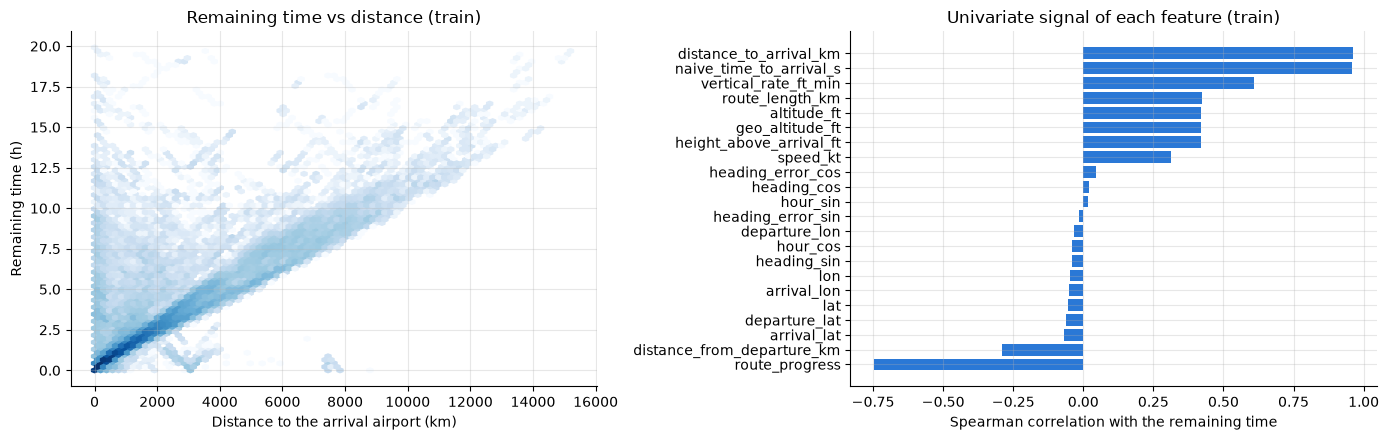

In [6]:
train = df[df["split"] == "train"]

last_minutes = train[train[LABEL] < 120]
print("Distance to the arrival airport during the last 2 minutes (km):")
display(last_minutes["distance_to_arrival_km"].quantile([0.5, 0.9, 0.99]).round(1).to_frame().T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hexbin(train["distance_to_arrival_km"], train[LABEL] / 3600,
               gridsize=80, bins="log", cmap="Blues", mincnt=1)
axes[0].set_xlabel("Distance to the arrival airport (km)")
axes[0].set_ylabel("Remaining time (h)")
axes[0].set_title("Remaining time vs distance (train)")

correlation = train[NUMERIC_FEATURES].corrwith(train[LABEL], method="spearman").sort_values()
axes[1].barh(correlation.index, correlation.values)
axes[1].set_xlabel("Spearman correlation with the remaining time")
axes[1].set_title("Univariate signal of each feature (train)")
plt.tight_layout()
plt.show()

**Takeaway.** The aircraft is indeed close to its arrival airport at the end of the flight (the remaining distances of a few kilometres to a few tens of kilometres correspond to the final approach; the last 1 %, still more than ~140 km away, are probably flights whose coverage stops before the landing or with a wrong arrival airport), and the distance to arrival is by far the most informative single feature: the relation is almost linear, with a spread due to the speed (climb, cruise, approach) and to holding patterns. The naive time to arrival carries the same ranking information and adds the speed: its actual contribution is measured in notebook 04 (ablation): it brings a real gain to the selected linear model (about 0.2 minute of MAE), mostly after the cruise. The vertical rate is also correlated with the label, but only through the flight structure: climbs happen early (long remaining time) and descents late.

## 4. Encoding and standardization (fitted on the training flights)

**Airports.** The coordinates now carry the geography of the airports. On top of that, an airport can have its own effects (approach procedures, congestion, holding patterns), so the airports are also one-hot encoded, but **only the frequent ones**: airports with fewer than 50 training flights are grouped into a single "infrequent" category, which is also used for airports never seen in training. This keeps a few hundred columns instead of thousands.

**Scaling.** The numeric features live on very different scales (kilometres, feet, sines). Standardization (zero mean, unit variance) is needed for the PCA below and for the linear models (L2 penalty, gradient descent); the tree-based models do not need it. The means and standard deviations are computed on the training flights only.

In [7]:
preprocessor = make_preprocessor()  # scaler + one-hot of the frequent airports
preprocessor.fit(train)

feature_names = preprocessor.get_feature_names_out()
n_airport_columns = sum(name.startswith("airports__") for name in feature_names)
print(f"{len(feature_names)} model columns: {len(NUMERIC_FEATURES)} numeric "
      f"+ {n_airport_columns} airport columns (including the 'infrequent' categories)")

scaler = preprocessor.named_transformers_["numeric"]
scaled = {
    name: pd.DataFrame(scaler.transform(df.loc[df["split"] == name, NUMERIC_FEATURES]),
                       columns=NUMERIC_FEATURES)
    for name in ["train", "validation"]
}
display(pd.DataFrame({
    name: {"max |mean|": data.mean().abs().max(), "min std": data.std().min(), "max std": data.std().max()}
    for name, data in scaled.items()
}).round(3))

254 model columns: 22 numeric + 232 airport columns (including the 'infrequent' categories)


,train,validation
max |mean|,0.0,0.018
min std,1.0,0.989
max std,1.0,1.014


## 5. PCA

10 components out of 22 explain 90 % of the variance


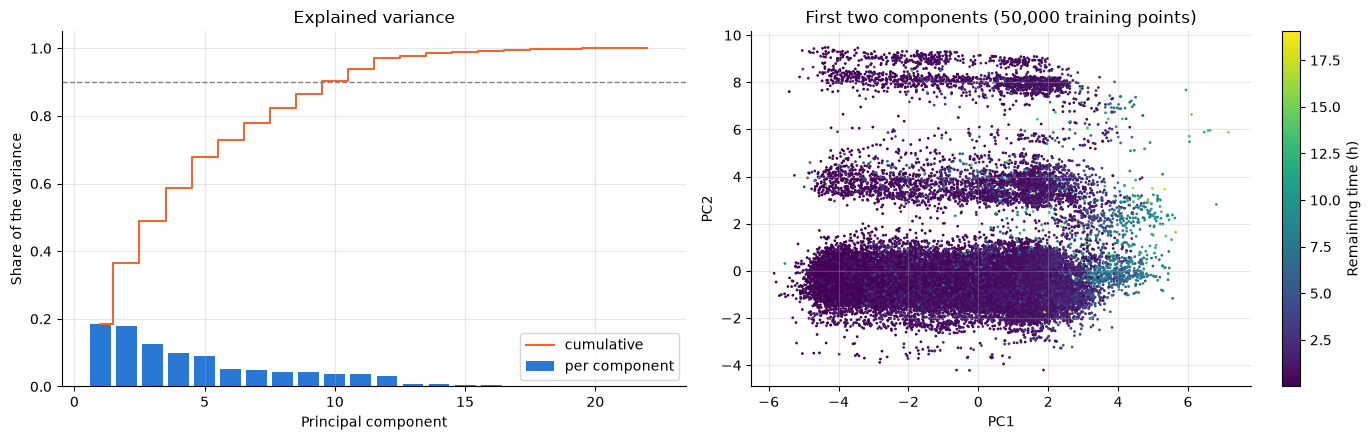

Correlation of the first components with the remaining time (training rows):


,PC1,PC2,PC3,PC4,PC5,PC6
correlation,0.36,0.07,0.73,0.2,0.18,-0.02


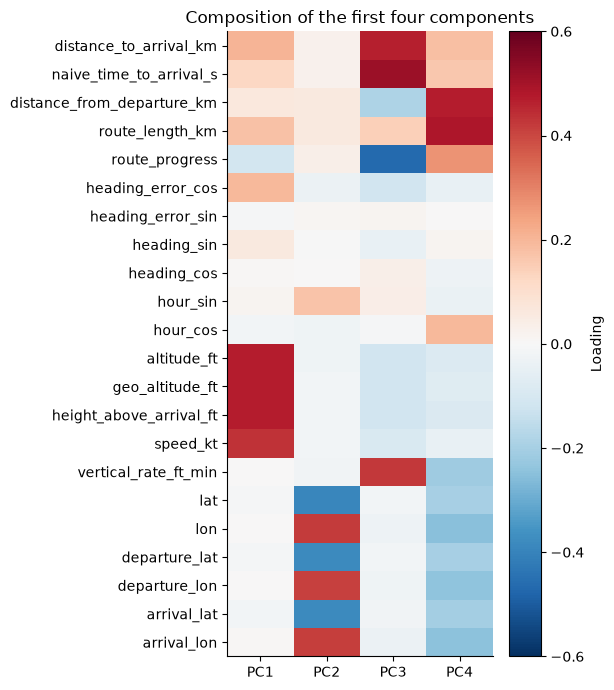

In [8]:
pca = PCA(random_state=RANDOM_STATE).fit(scaled["train"])
explained = pca.explained_variance_ratio_
n_90 = int(np.searchsorted(np.cumsum(explained), 0.9) + 1)
print(f"{n_90} components out of {len(NUMERIC_FEATURES)} explain 90 % of the variance")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
components = np.arange(1, len(explained) + 1)
axes[0].bar(components, explained, label="per component")
axes[0].step(components, np.cumsum(explained), where="mid", color=COLORS[1], label="cumulative")
axes[0].axhline(0.9, color="gray", linestyle="--", linewidth=1)
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Share of the variance")
axes[0].set_title("Explained variance")
axes[0].legend()

sample = scaled["train"].sample(50_000, random_state=RANDOM_STATE)
projected = pca.transform(sample)
labels = train[LABEL].to_numpy()[sample.index] / 3600
points = axes[1].scatter(projected[:, 0], projected[:, 1], c=labels, s=1, cmap="viridis")
fig.colorbar(points, ax=axes[1], label="Remaining time (h)")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("First two components (50,000 training points)")
plt.tight_layout()
plt.show()

# Correlation of each component with the remaining time (all the training rows)
train_components = pca.transform(scaled["train"])
correlation = pd.Series([np.corrcoef(train_components[:, i], train[LABEL])[0, 1] for i in range(6)],
                        index=[f"PC{i}" for i in range(1, 7)])
print("Correlation of the first components with the remaining time (training rows):")
display(correlation.round(2).to_frame("correlation").T)

loadings = pd.DataFrame(pca.components_[:4].T, index=NUMERIC_FEATURES,
                        columns=[f"PC{i}" for i in range(1, 5)])
fig, ax = plt.subplots(figsize=(6, 7))
image = ax.imshow(loadings, cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(4), loadings.columns)
ax.set_yticks(range(len(NUMERIC_FEATURES)), NUMERIC_FEATURES)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Loading")
ax.set_title("Composition of the first four components")
plt.tight_layout()
plt.show()

**Takeaway.** About ten components are needed to explain 90 % of the variance, and several features are redundant:
- PC1 gathers the two altitudes, the height above the arrival airport and the speed: the flight phase;
- PC2 gathers the positions and the airport coordinates: the region (the horizontal bands of the scatter plot are continents);
- PC3 gathers the naive time to arrival, the distance to arrival, the progress along the route and the vertical rate: how far the aircraft is from its destination;
- PC4 gathers the route length and the distance from departure.

The remaining time is mostly carried by PC3, the *third* component (correlation of 0.73 with the remaining time, against 0.36 for PC1 and at most 0.2 for the others): the directions with the most variance (phase, region) are not the most predictive ones.

## 6. Save the features

The saved table keeps the features **unscaled** (in physical units): each model fits and applies its own preprocessing.

In [9]:
FEATURES_PATH.parent.mkdir(parents=True, exist_ok=True)
df[FEATURE_TABLE_COLUMNS].to_parquet(FEATURES_PATH, index=False)  # the columns are listed in src/opensky_eta/dataset.py
print(f"Saved {FEATURES_PATH.relative_to(PROJECT_DIR)}: {len(df):,} rows, {len(FEATURE_TABLE_COLUMNS)} columns")

Saved data/processed/features/features.parquet: 2,056,320 rows, 31 columns


| Column(s) | Role |
|---|---|
| `NUMERIC_FEATURES`, `CATEGORICAL_FEATURES` | model inputs |
| `remaining_time` | label (seconds) |
| `split` | train / validation / test, by flight |
| `icao24`, `firstSeen`, `lastSeen`, `time` | identifiers (grouping, plots) |
| `phase_of_flight` | evaluation (MAE per segment); routing of the per-segment models of notebook 04 and one experiment of notebook 05, under the assumption of a phase of flight known at any time; never an input of the selected models |